# 🌍 Climate & Health Risk Prediction: an improved baseline

**Data Science Club hackathon: kick-off notebook**

The task: predict whether a recorded death in Uganda falls into a **climate-sensitive** category, using
age, gender, place, date and climate measurements.

This notebook is a **starting point, not a winning solution**. It improves on the original Zindi starter
notebook in two ways that matter more than any fancy model:

1. **Honest validation.** Test villages are *not* in the training data, so we validate on villages the model has
   never seen. The starter's random split is too optimistic.
2. **A few well-motivated features** (age groups, season) and a gradient-boosting model that comes with
   scikit-learn, so nothing extra needs installing.

| | Held-out-village validation score |
|---|---|
| Zindi starter (logistic regression) | ≈ 0.771 |
| **This notebook** | **≈ 0.80** |

There is plenty of room above this. The last section lists directions to explore.

**Runs on:** a laptop, Google Colab or Kaggle, CPU only, in about a minute.
**Inputs:** `Train.csv`, `Test.csv`, `climate_features.csv`. **Output:** `submission.csv`.

> **Data:** from the Zindi *Climate Risk Health Prediction Challenge*, shared under **CC BY-SA 4.0**. Keep this
> attribution if you share the data or anything derived from it.

## 1. Setup

We use only standard libraries: `pandas` and `numpy` for data, `scikit-learn` for models and metrics, and
`matplotlib` for plots. All the settings you might want to change are in the configuration cell further down.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import GroupKFold, train_test_split

warnings.filterwarnings("ignore")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.1.3


### Configuration

Everything you may want to change lives here, in one place:

- `DATA_DIR`: where the three CSV files are. It is found automatically on Kaggle (attached dataset), on Colab
  (files uploaded to `/content`) or next to this notebook.
- `N_FOLDS`: how many groups of villages we hold out in turn during validation.
- `SEED`: fixes the randomness so everyone gets the same numbers.
- `MODEL_PARAMS`: the gradient-boosting settings, each explained in its comment.

In [2]:
def find_data_dir() -> Path:
    """Return the first folder that contains Train.csv: here, ./data, /content (Colab) or a Kaggle input."""
    candidates = [Path("."), Path("data"), Path("/content")]
    if Path("/kaggle/input").exists():
        candidates += sorted(Path("/kaggle/input").glob("**/"))
    for folder in candidates:
        if (folder / "Train.csv").exists():
            return folder
    raise FileNotFoundError("Put Train.csv, Test.csv and climate_features.csv next to this notebook.")


DATA_DIR = Path(os.environ["DATA_DIR"]) if os.environ.get("DATA_DIR") else find_data_dir()
N_FOLDS = 5
SEED = 42
MODEL_PARAMS = dict(
    max_iter=300,           # number of boosting rounds (trees)
    learning_rate=0.05,     # how much each new tree corrects the previous ones
    max_leaf_nodes=15,      # small trees: the data has only about 3,000 rows
    min_samples_leaf=40,    # each leaf must cover at least 40 deaths, so it cannot memorise one village
    l2_regularization=1.0,  # extra shrinkage against overfitting
    random_state=SEED,
)
TARGET, ID_COL = "is_climate_sensitive", "ID"
print("Reading data from:", DATA_DIR.resolve())

Reading data from: /kaggle/input/datasets/moanlobago/climate-health-risk-hackathon-data


## 2. Data

Three files:

- `Train.csv`: one row per recorded death, with the target `is_climate_sensitive` (1 = climate-sensitive).
- `Test.csv`: the same columns without the target. These are what we predict.
- `climate_features.csv`: extra climate and environment measurements per death (rain and temperature over the
  previous 7, 30 and 90 days, the vegetation index NDVI, elevation, slope). We join it on `ID`.

The `deathdate` column also appears in the climate file, so we drop that copy before joining.

In [3]:
train = pd.read_csv(DATA_DIR / "Train.csv")
test = pd.read_csv(DATA_DIR / "Test.csv")
climate = pd.read_csv(DATA_DIR / "climate_features.csv").drop(columns=["deathdate"])

train = train.merge(climate, on=ID_COL, how="left")
test = test.merge(climate, on=ID_COL, how="left")
print("train:", train.shape, "| test:", test.shape)
train.head(3)

train: (3146, 29) | test: (1030, 28)


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,...,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,...,175.264057,28.419111,421.992750,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,...,71.885960,0.000000,268.439276,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,...,108.145379,35.970423,242.081887,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068


### A first look at the target and at age

About 65% of the deaths are climate-sensitive, so the classes are imbalanced but not extremely.

Age is the strongest signal. Many climate-sensitive causes of death (for example malaria, diarrhoea and
respiratory infections) hit **young children** hardest. The plot shows the share of climate-sensitive deaths by
age group.

Share of climate-sensitive deaths: 0.651


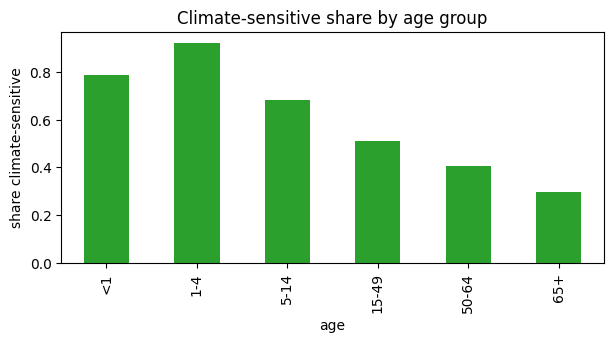

,mean,size
age,,
<1,0.787770,1112
1-4,0.922705,621
5-14,0.683761,117
15-49,0.510476,525
50-64,0.406091,197
65+,0.296167,574


In [4]:
print("Share of climate-sensitive deaths:", round(train[TARGET].mean(), 3))

age_groups = pd.cut(train["age"], [-0.1, 0.99, 4.99, 14.99, 49.99, 64.99, 200],
                    labels=["<1", "1-4", "5-14", "15-49", "50-64", "65+"])
share = train.groupby(age_groups, observed=True)[TARGET].agg(["mean", "size"])
ax = share["mean"].plot(kind="bar", figsize=(7, 3), color="tab:green")
ax.set_ylabel("share climate-sensitive")
ax.set_title("Climate-sensitive share by age group")
plt.show()
share

## 3. The most important lesson: validate the way you will be tested

The test set comes from **villages that are (almost) never in the training data**: only 1 of the 11 test
villages also appears in train. A model can partly learn *which village* a death came from, and that knowledge is
useless on new villages.

- The starter notebook used a **random** 80/20 split. Deaths from the same village land on both sides, so the
  score looks better than it really is.
- We use **GroupKFold by village** (`location`): each fold holds out whole villages, exactly like the test.

The next cell counts the villages and defines the official score.

In [5]:
villages = train["location"].values
y = train[TARGET].values
print("villages in train:", train["location"].nunique(), "| in test:", test["location"].nunique(),
      "| in both:", len(set(train["location"]) & set(test["location"])))


def competition_score(y_true, proba) -> float:
    """Official metric: 0.6 x F1 (labels from the fixed 0.5 cut) + 0.4 x ROC-AUC (on the probabilities)."""
    return 0.6 * f1_score(y_true, (proba >= 0.5).astype(int)) + 0.4 * roc_auc_score(y_true, proba)

villages in train: 39 | in test: 11 | in both: 1


## 4. Features

We start from the original columns and the climate file, then add a few features with a clear reason:

| Feature | Why |
|---|---|
| `is_infant`, `is_under5`, `is_elderly`, `age_log` | the risk is very different for babies, small children and the elderly |
| `month_sin`, `month_cos` | season (rainy and dry seasons drive malaria and diarrhoea); sine and cosine put December next to January |
| `day_of_year`, `year` | finer timing, and slow changes over the years |
| `temperature_range`, `is_rainy_day_current` | kept from the starter notebook |
| `zone`, `gender` | turned into 0/1 columns |

We **drop** `location`, `latitude` and `longitude`. They identify the village, so a model could memorise
villages instead of learning patterns that carry over to new ones.

In [6]:
def make_features(df: pd.DataFrame) -> pd.DataFrame:
    """Turn the raw table into model inputs. Same steps for train and test; uses no target information."""
    out = df.copy()
    date = pd.to_datetime(out["deathdate"], errors="coerce")
    out["day_of_year"] = date.dt.dayofyear
    out["year"] = date.dt.year
    out["month_sin"] = np.sin(2 * np.pi * date.dt.month / 12)
    out["month_cos"] = np.cos(2 * np.pi * date.dt.month / 12)

    out["is_infant"] = (out["age"] < 1).astype(int)
    out["is_under5"] = (out["age"] < 5).astype(int)
    out["is_elderly"] = (out["age"] >= 65).astype(int)
    out["age_log"] = np.log1p(out["age"])

    out["temperature_range"] = out["max_temperature"] - out["min_temperature"]
    out["is_rainy_day_current"] = (out["precipitation"] > 0).astype(int)
    out["zone"] = (out["zone"] == "Rural").astype(int)
    out["gender"] = (out["gender"] == "Male").astype(int)

    drop = [ID_COL, TARGET, "deathdate", "location", "latitude", "longitude"]
    return out.drop(columns=[c for c in drop if c in out.columns])


X = make_features(train)
X_test = make_features(test)
print(X.shape[1], "features:", ", ".join(X.columns))

33 features: zone, gender, age, avg_temperature, max_temperature, min_temperature, precipitation, elevation, hot_days_30d, max_daily_rain_30d, ndvi_30d, ndvi_90d, rain_days_30d, rain_sum_30d, rain_sum_7d, rain_sum_90d, slope, tavg_30d, tavg_7d, tavg_90d, temp_range_mean_30d, tmax_30d, tmin_30d, day_of_year, year, month_sin, month_cos, is_infant, is_under5, is_elderly, age_log, temperature_range, is_rainy_day_current


## 5. Random split vs village split

The same model, measured two ways. For this model the two numbers are close (about 0.806 vs 0.804), because it
cannot see the village columns. The starter's logistic regression shows the trap: **0.806 on a random split but
only 0.771 on held-out villages.** Every new idea must be checked with the village split, since a feature that
leaks village identity looks great on a random split and fails on the test. From here on we only trust the
village split.

In [7]:
def village_cv(make_model, X: pd.DataFrame, y: np.ndarray, groups: np.ndarray, n_folds: int = N_FOLDS):
    """Train on some villages and predict the held-out ones, once per fold.

    Returns the out-of-fold probabilities (one per training row) and the score of each fold."""
    oof = np.zeros(len(y))
    fold_scores = []
    for train_idx, valid_idx in GroupKFold(n_splits=n_folds).split(X, y, groups):
        model = make_model().fit(X.iloc[train_idx], y[train_idx])
        oof[valid_idx] = model.predict_proba(X.iloc[valid_idx])[:, 1]
        fold_scores.append(competition_score(y[valid_idx], oof[valid_idx]))
    return oof, np.array(fold_scores)


def make_model():
    """The baseline model: scikit-learn's histogram gradient boosting (it handles missing values itself)."""
    return HistGradientBoostingClassifier(**MODEL_PARAMS)


idx_train, idx_valid = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=y)
random_split_score = competition_score(
    y[idx_valid], make_model().fit(X.iloc[idx_train], y[idx_train]).predict_proba(X.iloc[idx_valid])[:, 1])
oof, fold_scores = village_cv(make_model, X, y, villages)

print(f"random 80/20 split : {random_split_score:.4f}   <- optimistic")
print(f"village GroupKFold : {fold_scores.mean():.4f} ± {fold_scores.std():.4f}   <- what to trust")

random 80/20 split : 0.8063   <- optimistic
village GroupKFold : 0.8040 ± 0.0117   <- what to trust


## 6. Results of the baseline

The village-split score is our honest estimate. The fold-to-fold spread (±) shows how much a score moves just
from *which* villages are held out, so **a change smaller than about 0.01 may be noise**.

Below we split the score into its two parts and look at age groups, which shows where the model is weak.

In [8]:
labels = (oof >= 0.5).astype(int)
print(f"F1 (60%)      : {f1_score(y, labels):.4f}")
print(f"ROC-AUC (40%) : {roc_auc_score(y, oof):.4f}")
print(f"overall       : {competition_score(y, oof):.4f}")

report = pd.DataFrame({"age group": age_groups, "y": y, "label": labels})
by_age = report.groupby("age group", observed=True).agg(
    deaths=("y", "size"), true_share=("y", "mean"))
by_age["accuracy"] = report.assign(ok=report["label"] == report["y"]).groupby("age group", observed=True)["ok"].mean()
by_age.round(3)

F1 (60%)      : 0.7995
ROC-AUC (40%) : 0.8096
overall       : 0.8035


,deaths,true_share,accuracy
age group,,,
<1,1112,0.788,0.772
1-4,621,0.923,0.921
5-14,117,0.684,0.624
15-49,525,0.510,0.556
50-64,197,0.406,0.604
65+,574,0.296,0.693


### Which features does the model use?

Permutation importance: shuffle one feature at a time on held-out villages and measure how much ROC-AUC drops.
A big drop means the model relies on that feature. We use the last fold's villages, so the measurement is on
data the model has not seen.

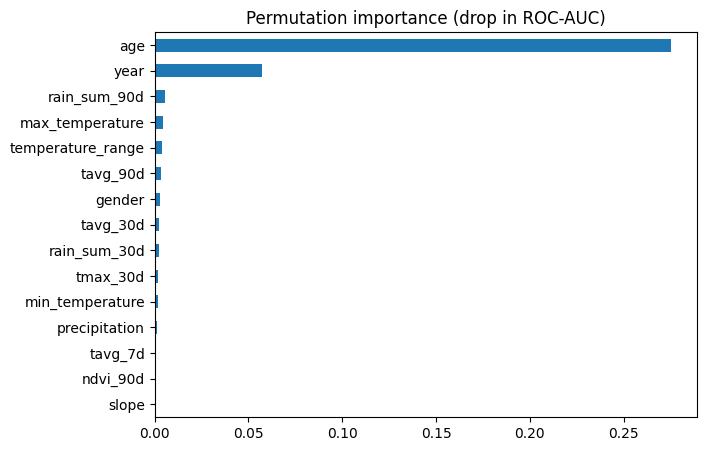

In [9]:
train_idx, valid_idx = list(GroupKFold(n_splits=N_FOLDS).split(X, y, villages))[-1]
model = make_model().fit(X.iloc[train_idx], y[train_idx])
result = permutation_importance(model, X.iloc[valid_idx], y[valid_idx], scoring="roc_auc",
                                n_repeats=10, random_state=SEED)
importance = pd.Series(result.importances_mean, index=X.columns).sort_values()
importance.tail(15).plot(kind="barh", figsize=(7, 5), title="Permutation importance (drop in ROC-AUC)")
plt.show()

## 7. Train on all the data and write the submission

We refit the same model on every training row and predict the test set.

The submission needs two columns:

- `TargetF1`: the 0/1 label. **The rules require the default 0.5 cut-off; tuning the threshold is forbidden.**
- `TargetRAUC`: the raw probability (do not round it).

In [10]:
final_model = make_model().fit(X, y)
test_proba = final_model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    ID_COL: test[ID_COL],
    "TargetF1": (test_proba >= 0.5).astype(int),
    "TargetRAUC": test_proba,
})
assert len(submission) == len(test) and submission[ID_COL].is_unique
submission.to_csv("submission.csv", index=False)
print("Saved submission.csv:", submission.shape, "| predicted climate-sensitive share:",
      round(submission["TargetF1"].mean(), 3))
submission.head()

Saved submission.csv: (1030, 3) | predicted climate-sensitive share: 0.702


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,0,0.229960
1,ID_6EDEA907,1,0.897318
2,ID_B9FFC8D8,1,0.563212
3,ID_74C6C94E,1,0.628907
4,ID_0E02825D,1,0.845278


## 8. Where to go from here

Ideas, roughly from easiest to hardest. Always compare with the **village** score from section 5, never the
random split, and remember the ± spread.

1. **Tune the model** (`MODEL_PARAMS`): number of trees, tree size, regularisation. Try LightGBM, XGBoost or
   CatBoost.
2. **Average several different models**, for example this one with a logistic regression on the same features.
   Different models make different mistakes, and averaging probabilities often helps both F1 and AUC.
3. **Better age features.** Age is the strongest signal. How does the risk change *within* the first year of
   life, or between 1 and 5?
4. **Climate anomalies.** Is it unusually wet or hot *for that place and season*? Compare the 7/30/90-day values
   with the location's typical values (computed without the target).
5. **Interactions.** Does rain matter more for small children? Trees find some of this; explicit features can help.
6. **Robust validation.** Repeat GroupKFold with different village groupings and average, so you don't chase noise.

**Rules to respect:** do not tune the 0.5 threshold; open-source tools only; use the test set only for prediction.

Good luck, and have fun! 🚀